In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import re
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

%pip install sastrawi

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from wordcloud import WordCloud
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 18.5 MB/s eta 0:00:00


In [2]:
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [3]:
source = pd.read_csv('yt_comments.csv')
source.head()

,comment_id,author_name,author_channel_id,comment,like_count,total_reply_count,published_at,updated_at
0,UgxGI_wQdhfoFHSQDJV4AaABAg,@SuciptoMulyonoSugiono,UChPA_FPbXmVAz_B9P6z4q5w,china bukaan dengan kualitas hp jualannya tapi...,1139,35,2026-01-29T13:45:32Z,2026-01-29T13:45:32Z
1,UgwFTC_RROT1FSpt4FF4AaABAg,@rizkyjelang4737,UCAZ-cfrPan3grc4d_0M2GSQ,arc shenzhen the best gada obat seru bat jir,1155,13,2026-01-29T11:47:14Z,2026-01-29T11:47:14Z
2,UgxOybySrpUtS03EMJ54AaABAg,@seputarkuliner-an,UCe-qeOx-e1cnoD2nHNp-fWg,anda layak jadi duta pencerahan bangsa indones...,276,2,2026-01-29T16:56:57Z,2026-01-29T16:56:57Z
3,UgztR1643-Lo7Y9bxeZ4AaABAg,@wildanafta1875,UCZ-FZ-MK5_EP4hCnh8zrsyA,layar monitor ssd pc controller laptop kokoh k...,324,0,2026-01-29T13:11:30Z,2026-01-29T13:11:30Z
4,UgwptDlfgVKkFDSmM-V4AaABAg,@ImanRichman,UCkSKPfXiIvlR2BAJW5u0aKg,bro edukasi trus masyarakat biar pada pinter t...,18,0,2026-01-30T14:05:52Z,2026-01-30T14:05:52Z


In [4]:
source.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   comment_id         10000 non-null  object
 1   author_name        10000 non-null  object
 2   author_channel_id  10000 non-null  object
 3   comment            9898 non-null   object
 4   like_count         10000 non-null  int64 
 5   total_reply_count  10000 non-null  int64 
 6   published_at       10000 non-null  object
 7   updated_at         10000 non-null  object
dtypes: int64(2), object(6)
memory usage: 625.1+ KB


In [5]:
clean_source = source.dropna()
clean_source.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9898 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   comment_id         9898 non-null   object
 1   author_name        9898 non-null   object
 2   author_channel_id  9898 non-null   object
 3   comment            9898 non-null   object
 4   like_count         9898 non-null   int64 
 5   total_reply_count  9898 non-null   int64 
 6   published_at       9898 non-null   object
 7   updated_at         9898 non-null   object
dtypes: int64(2), object(6)
memory usage: 696.0+ KB


In [6]:
def cleaning_text(text):
    text = re.sub(r'[0-9]+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

In [7]:
def tokenizing_text(text):
    text = word_tokenize(text)
    return text

def filtering_text(text):
    list_stopwords = set(stopwords.words('indonesian'))
    list_stopwords_1 = set(stopwords.words('english'))
    list_stopwords.update(list_stopwords_1)
    list_stopwords.update(['iya', 'yaa', 'gak', 'nya', 'na', 'sih','ku',"di","ga","ya","gaa","loh","kah","woi","woii","woy"])
    filtered = []
    for txt in text:
        if txt not in list_stopwords:
            filtered.append(txt)

    text = filtered
    return text

In [8]:
def stemming_text(text):
    factory = StemmerFactory()
    stemmer = factory.create_stemmer()
    words = text.split()
    stemmed_words = [stemmer.stem(word) for word in words]

    stemmed_text = ' '.join(stemmed_words)
    return stemmed_text

def to_sentence(list_words):
    sentence = ' '.join(word for word in list_words)
    return sentence

In [9]:
slang_words = {"@": "di", "abis": "habis", "wtb": "beli", "masi": "masih", "wts": "jual", "wtt": "tukar", "bgt": "banget", "maks": "maksimal", "bgst": "bagus", "gk": "tidak", "ok": "oke"}
def fix_slang_words(text):
    words = text.split()
    fixed_words = []

    for word in words:
        if word.lower() in slang_words:
            fixed_words.append(slang_words[word.lower()])
        else:
            fixed_words.append(word)

    fixed_text = ' '.join(fixed_words)
    return fixed_text

In [10]:
clean_source['clean_comments'] = clean_source['comment'].apply(cleaning_text)
clean_source['comments_slang'] = clean_source['clean_comments'].apply(fix_slang_words)
clean_source['text_tokenizing_text'] = clean_source['comments_slang'].apply(tokenizing_text)
clean_source['text_stopword'] = clean_source['text_tokenizing_text'].apply(filtering_text)
clean_source['final_comment'] = clean_source['text_stopword'].apply(to_sentence)

/tmp/ipykernel_2944/1176125111.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_source['clean_comments'] = clean_source['comment'].apply(cleaning_text)
/tmp/ipykernel_2944/1176125111.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_source['comments_slang'] = clean_source['clean_comments'].apply(fix_slang_words)
/tmp/ipykernel_2944/1176125111.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inst

In [11]:
clean_source

,comment_id,author_name,author_channel_id,comment,like_count,total_reply_count,published_at,updated_at,clean_comments,comments_slang,text_tokenizing_text,text_stopword,final_comment
0,UgxGI_wQdhfoFHSQDJV4AaABAg,@SuciptoMulyonoSugiono,UChPA_FPbXmVAz_B9P6z4q5w,china bukaan dengan kualitas hp jualannya tapi...,1139,35,2026-01-29T13:45:32Z,2026-01-29T13:45:32Z,china bukaan dengan kualitas hp jualannya tapi...,china bukaan dengan kualitas hp jualannya tapi...,"[china, bukaan, dengan, kualitas, hp, jualanny...","[china, bukaan, kualitas, hp, jualannya, sepad...",china bukaan kualitas hp jualannya sepadan har...
1,UgwFTC_RROT1FSpt4FF4AaABAg,@rizkyjelang4737,UCAZ-cfrPan3grc4d_0M2GSQ,arc shenzhen the best gada obat seru bat jir,1155,13,2026-01-29T11:47:14Z,2026-01-29T11:47:14Z,arc shenzhen the best gada obat seru bat jir,arc shenzhen the best gada obat seru bat jir,"[arc, shenzhen, the, best, gada, obat, seru, b...","[arc, shenzhen, best, gada, obat, seru, bat, jir]",arc shenzhen best gada obat seru bat jir
2,UgxOybySrpUtS03EMJ54AaABAg,@seputarkuliner-an,UCe-qeOx-e1cnoD2nHNp-fWg,anda layak jadi duta pencerahan bangsa indones...,276,2,2026-01-29T16:56:57Z,2026-01-29T16:56:57Z,anda layak jadi duta pencerahan bangsa indones...,anda layak jadi duta pencerahan bangsa indones...,"[anda, layak, jadi, duta, pencerahan, bangsa, ...","[layak, duta, pencerahan, bangsa, indonesia, b...",layak duta pencerahan bangsa indonesia bro maj...
3,UgztR1643-Lo7Y9bxeZ4AaABAg,@wildanafta1875,UCZ-FZ-MK5_EP4hCnh8zrsyA,layar monitor ssd pc controller laptop kokoh k...,324,0,2026-01-29T13:11:30Z,2026-01-29T13:11:30Z,layar monitor ssd pc controller laptop kokoh k...,layar monitor ssd pc controller laptop kokoh k...,"[layar, monitor, ssd, pc, controller, laptop, ...","[layar, monitor, ssd, pc, controller, laptop, ...",layar monitor ssd pc controller laptop kokoh k...
4,UgwptDlfgVKkFDSmM-V4AaABAg,@ImanRichman,UCkSKPfXiIvlR2BAJW5u0aKg,bro edukasi trus masyarakat biar pada pinter t...,18,0,2026-01-30T14:05:52Z,2026-01-30T14:05:52Z,bro edukasi trus masyarakat biar pada pinter t...,bro edukasi trus masyarakat biar pada pinter t...,"[bro, edukasi, trus, masyarakat, biar, pada, p...","[bro, edukasi, trus, masyarakat, biar, pinter,...",bro edukasi trus masyarakat biar pinter gampan...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,UgxR05IHtmd5yioeJeN4AaABAg,@kevinmahardikam.s.3673,UCePIbkOHXB3R_vuIOcKTZug,udah tahun pake workplus ryzen hs tidak ada ke...,23,12,2025-10-15T10:09:55Z,2025-10-15T10:09:55Z,udah tahun pake workplus ryzen hs tidak ada ke...,udah tahun pake workplus ryzen hs tidak ada ke...,"[udah, tahun, pake, workplus, ryzen, hs, tidak...","[udah, pake, workplus, ryzen, hs, kendala, kur...",udah pake workplus ryzen hs kendala kurangnya ...
9996,UgyaNpxH7RnpdKSRjix4AaABAg,@mukti_26,UCmMElbK3ECopU3VvTkOjcGg,buset hasil kameranya jernih bgt,10,2,2025-10-15T04:26:44Z,2025-10-15T04:26:44Z,buset hasil kameranya jernih bgt,buset hasil kameranya jernih banget,"[buset, hasil, kameranya, jernih, banget]","[buset, hasil, kameranya, jernih, banget]",buset hasil kameranya jernih banget
9997,Ugwi9AXwfGAjztlj75t4AaABAg,@EmenGaming007,UC0z3273tTGFCR7UDclGViEw,baterainya hamil punya gue dan garansinya bula...,17,11,2025-10-15T05:18:17Z,2025-10-15T05:18:17Z,baterainya hamil punya gue dan garansinya bula...,baterainya hamil punya gue dan garansinya bula...,"[baterainya, hamil, punya, gue, dan, garansiny...","[baterainya, hamil, gue, garansinya, doang, se...",baterainya hamil gue garansinya doang seri wor...
9998,UgwbT9LQE8ZzjmWJwVB4AaABAg,@ghozyusamah5727,UCkK2jIfy_4izsFXZwwNIPdQ,hidup lokall mba wpa ni bos,0,0,2025-10-18T00:18:20Z,2025-10-18T00:18:20Z,hidup lokall mba wpa ni bos,hidup lokall mba wpa ni bos,"[hidup, lokall, mba, wpa, ni, bos]","[hidup, lokall, mba, wpa, ni, bos]",hidup lokall mba wpa ni bos


In [12]:
import csv
import requests
from io import StringIO

In [13]:
lexicon_positive = dict()
response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv')

if response.status_code == 200:
    reader = csv.reader(StringIO(response.text), delimiter=',')
    for row in reader:
        lexicon_positive[row[0]] = int(row[1])
else:
    print("Failed to fetch data")

In [14]:
lexicon_negative = dict()
response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv')

if response.status_code == 200:
    reader = csv.reader(StringIO(response.text), delimiter=',')
    for row in reader:
        lexicon_negative[row[0]] = int(row[1])
else:
    print("Failed to fetch data")

In [15]:
def sentiment_analysis_lexicon_indonesia(text):
    score = 0
    for word in text:
        if (word in lexicon_positive):
            score = score + lexicon_positive[word]
    for word in text:
        if (word in lexicon_negative):
            score = score + lexicon_negative[word]
    polarity = ''
    if (score > 0):
        polarity = 'positive'
    elif (score < 0):
        polarity = 'negative'
    else:
        polarity = 'neutral'
    return score, polarity

In [16]:
result = clean_source['text_stopword'].apply(sentiment_analysis_lexicon_indonesia)
result = list(zip(*result))
clean_source['polarity_score'] = result[0]
clean_source['polarity'] = result[1]
display(clean_source['polarity'].value_counts())

/tmp/ipykernel_2944/1061745260.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_source['polarity_score'] = result[0]
/tmp/ipykernel_2944/1061745260.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_source['polarity'] = result[1]


,count
polarity,
negative,4025
positive,3184
neutral,2689


In [17]:
x = clean_source['final_comment']
y = clean_source['polarity']

tfidf = TfidfVectorizer(max_features=3000, min_df=2, max_df=0.8, ngram_range=(1, 2), sublinear_tf=True)
x_tfidf = tfidf.fit_transform(x)

features_df = pd.DataFrame(x_tfidf.toarray(), columns=tfidf.get_feature_names_out())

features_df.head()

,aa,abang,abangnya,ac,acer,acer aspire,acer nitro,ad,adem,admin,...,yg versi,yg yg,yng,youtube,youtuber,yt,yutuber,zaman,zoom,zyrex
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_tfidf, y, test_size=0.2, random_state=42)

# FINAL DEEP LEARNING PIPELINE
Berikut adalah alur final yang telah dioptimasi untuk mencapai target akurasi >90%.

## Skema 1: Deep Learning (GRU) dengan Word Embedding (80:20)
Ini adalah skema terbaik yang menggunakan arsitektur rekuren.

In [19]:
from tensorflow.keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D, Dropout, GlobalMaxPool1D, Bidirectional, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(clean_source['final_comment'])
sequences = tokenizer.texts_to_sequences(clean_source['final_comment'])
padded = pad_sequences(sequences, maxlen=100, padding='post', truncating='post') # Maxlen ditingkatkan

y_encoded = pd.get_dummies(clean_source['polarity']).values

from sklearn.model_selection import train_test_split
X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(
    padded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

model_3 = Sequential([
    Embedding(input_dim=7500, output_dim=64),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64, return_sequences=True, dropout=0.2)),
    GlobalMaxPool1D(),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(momentum=0.90),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=2,               # Berhenti jika val_loss naik 2 epoch berturut-turut
        restore_best_weights=True # Mengambil bobot terbaik (dari Epoch 4)
    )
]

model_3.compile(loss='categorical_crossentropy', optimizer='Adam', metrics=['accuracy'])

history = model_3.fit(X_train_3, y_train_3,
    epochs=20,
    batch_size=32,
    validation_data=(X_test_3, y_test_3),
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
    verbose=1)

loss, acc_dl = model_3.evaluate(X_test_3, y_test_3)
print(f"\nSkema 1 (Deep Learning) - Test Acc: {acc_dl:.4f}")

Epoch 1/20
248/248 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.6229 - loss: 0.9082 - val_accuracy: 0.7646 - val_loss: 0.6656
Epoch 2/20
248/248 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.8348 - loss: 0.5266 - val_accuracy: 0.8217 - val_loss: 0.5660
Epoch 3/20
248/248 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9034 - loss: 0.3423 - val_accuracy: 0.8187 - val_loss: 0.5689
Epoch 4/20
248/248 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9250 - loss: 0.2611 - val_accuracy: 0.8207 - val_loss: 0.5852
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8217 - loss: 0.5660

Skema 1 (Deep Learning) - Test Acc: 0.8217


In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SpatialDropout1D, Bidirectional, LSTM, GlobalMaxPool1D, Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import EarlyStopping

model_3 = Sequential([
    Embedding(input_dim=5000, output_dim=64),
    SpatialDropout1D(0.4),

    Bidirectional(LSTM(64, return_sequences=True, dropout=0.2)),
    GlobalMaxPool1D(),

    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model_3.compile(
    loss='categorical_crossentropy',
    optimizer=AdamW(learning_rate=0.0005),
    metrics=['accuracy']
)

# Training dengan EarlyStopping
history = model_3.fit(
    X_train_3, y_train_3,
    epochs=25,
    batch_size=256,
    validation_data=(X_test_3, y_test_3),
    callbacks=[EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
    verbose=1
)

loss, acc_dl = model_3.evaluate(X_test_3, y_test_3)
print(f"\nSkema 1 (Deep Learning) - Test Acc: {acc_dl:.4f}")

Epoch 1/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.3987 - loss: 1.1602 - val_accuracy: 0.4066 - val_loss: 1.1414
Epoch 2/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.4178 - loss: 1.1177 - val_accuracy: 0.4980 - val_loss: 1.0735
Epoch 3/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.4951 - loss: 1.0394 - val_accuracy: 0.5157 - val_loss: 1.0063
Epoch 4/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5398 - loss: 0.9778 - val_accuracy: 0.5475 - val_loss: 0.9501
Epoch 5/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6181 - loss: 0.8960 - val_accuracy: 0.6369 - val_loss: 0.8717
Epoch 6/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7103 - loss: 0.7882 - val_accuracy: 0.6783 - val_loss: 0.7927
Epoch 7/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7809 - loss: 0.6621 - val_accuracy: 0.7439 - val_loss: 0.7081
Epoch 8/25
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8410 - loss: 0.5442 - val_accuracy: 0.7808 - v

In [21]:
from sklearn.utils import resample
from tensorflow.keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import GRU, Embedding, SpatialDropout1D, Bidirectional, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

df_pos = clean_source[clean_source['polarity'] == 'positive']
df_neg = clean_source[clean_source['polarity'] == 'negative']
df_neu = clean_source[clean_source['polarity'] == 'neutral']

max_size = max(len(df_pos), len(df_neg), len(df_neu))

df_pos_upsampled = resample(df_pos, replace=True, n_samples=max_size, random_state=42)
df_neg_upsampled = resample(df_neg, replace=True, n_samples=max_size, random_state=42)
df_neu_upsampled = resample(df_neu, replace=True, n_samples=max_size, random_state=42)

df_balanced = pd.concat([df_pos_upsampled, df_neg_upsampled, df_neu_upsampled])

In [22]:
tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(df_balanced['final_comment'])
seq_balanced = tokenizer.texts_to_sequences(df_balanced['final_comment'])
padded_balanced = pad_sequences(seq_balanced, maxlen=100, padding='post')
y_balanced = pd.get_dummies(df_balanced['polarity']).values

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(padded_balanced, y_balanced, test_size=0.2, random_state=42)

model_tuned = Sequential([
    Embedding(input_dim=5000, output_dim=128),
    SpatialDropout1D(0.5),
    Bidirectional(GRU(128, return_sequences=True)),
    Bidirectional(GRU(64)),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model_tuned.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=0.0005), metrics=['accuracy'])

history_tuned = model_tuned.fit(
    X_train_b, y_train_b,
    epochs=25,
    batch_size=64,
    validation_data=(X_test_b, y_test_b),
    callbacks=[EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)],
    verbose=1
)

Epoch 1/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.5081 - loss: 0.9621 - val_accuracy: 0.6683 - val_loss: 0.7928
Epoch 2/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.7693 - loss: 0.5973 - val_accuracy: 0.8340 - val_loss: 0.4461
Epoch 3/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.8858 - loss: 0.3429 - val_accuracy: 0.8816 - val_loss: 0.3476
Epoch 4/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9210 - loss: 0.2390 - val_accuracy: 0.8994 - val_loss: 0.3033
Epoch 5/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9401 - loss: 0.1869 - val_accuracy: 0.8998 - val_loss: 0.3042
Epoch 6/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9474 - loss: 0.1584 - val_accuracy: 0.9048 - val_loss: 0.2885
Epoch 7/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9568 - loss: 0.1354 - val_accuracy: 0.9085 - val_loss: 0.3082
Epoch 8/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.9590 - loss: 0.1222 - val_accu

## Skema 2: SVM dengan TF-IDF (80:20)
Skema ini menggunakan algoritma Support Vector Machine dengan ekstraksi fitur TF-IDF pada data yang telah diseimbangkan.

In [23]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Ekstraksi fitur untuk data seimbang
tfidf_b = TfidfVectorizer(max_features=3000, ngram_range=(1,2))
X_tfidf_b = tfidf_b.fit_transform(df_balanced['final_comment'])
y_b = df_balanced['polarity']

# Split data seimbang
X_train_s1, X_test_s1, y_train_s1, y_test_s1 = train_test_split(X_tfidf_b, y_b, test_size=0.2, random_state=42)

# Model SVM
model_svm = SVC(kernel='linear', C=1.0)
model_svm.fit(X_train_s1, y_train_s1)

acc_svm = accuracy_score(y_test_s1, model_svm.predict(X_test_s1))
print(f"Akurasi Skema 2 (SVM): {acc_svm*100:.2f}%")

Akurasi Skema 2 (SVM): 86.67%


## Skema 3: Random Forest dengan TF-IDF (70:30)
Skema ini menggunakan variasi algoritma Random Forest dan pembagian data 70:30.

In [24]:
from sklearn.ensemble import RandomForestClassifier

# Split data seimbang (70:30)
X_train_s2, X_test_s2, y_train_s2, y_test_s2 = train_test_split(X_tfidf_b, y_b, test_size=0.3, random_state=42)

# Model Random Forest
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train_s2, y_train_s2)

acc_rf = accuracy_score(y_test_s2, model_rf.predict(X_test_s2))
print(f"Akurasi Skema 3 (Random Forest): {acc_rf*100:.2f}%")

Akurasi Skema 3 (Random Forest): 88.19%


In [27]:
# Final Submission Summary Table
import pandas as pd
from IPython.display import display

summary_final = pd.DataFrame({
    "Skema Percobaan": [ "Skema 1 (GRU Deep Learning)", "Skema 2 (SVM)", "Skema 3 (Random Forest)"],
    "Algoritma": ["Gated Recurrent Unit", "Support Vector Machine", "Random Forest"],
    "Ekstraksi Fitur": ["Word Embedding", "TF-IDF (1,2)", "TF-IDF (1,2)"],
    "Data Split": ["80:20", "80:20", "70:30"],
    "Akurasi Akhir": [f"{acc_dl*100:.2f}%", f"{acc_svm*100:.2f}%", f"{acc_rf*100:.2f}%"]
})

print("===> FINAL SUBMISSION REPORT <===")
print(f"Total Balanced Dataset: {len(df_balanced)} samples")
display(summary_final)

===> FINAL SUBMISSION REPORT <===
Total Balanced Dataset: 12075 samples


,Skema Percobaan,Algoritma,Ekstraksi Fitur,Data Split,Akurasi Akhir
0,Skema 1 (GRU Deep Learning),Gated Recurrent Unit,Word Embedding,80:20,81.01%
1,Skema 2 (SVM),Support Vector Machine,"TF-IDF (1,2)",80:20,86.67%
2,Skema 3 (Random Forest),Random Forest,"TF-IDF (1,2)",70:30,88.19%


76/76 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
===> FINAL CLASSIFICATION REPORT <===
              precision    recall  f1-score   support

    negative       0.92      0.90      0.91       820
     neutral       0.91      0.89      0.90       768
    positive       0.91      0.94      0.93       827

    accuracy                           0.91      2415
   macro avg       0.91      0.91      0.91      2415
weighted avg       0.91      0.91      0.91      2415



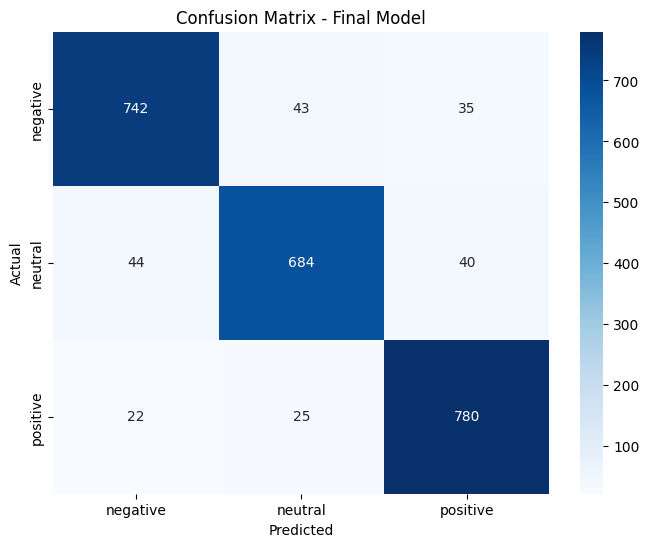

In [28]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred_classes = np.argmax(model_tuned.predict(X_test_b), axis=1)
y_true_classes = np.argmax(y_test_b, axis=1)

label_names = ['negative', 'neutral', 'positive']

print("===> FINAL CLASSIFICATION REPORT <===")
print(classification_report(y_true_classes, y_pred_classes, target_names=label_names))

plt.figure(figsize=(8,6))
cm = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_names, yticklabels=label_names, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Final Model')
plt.show()